# Bank Marketing
The Bank Marketing dataset contains information about bank customers, their demographics, contact methods, campaign history, and whether they subscribed to a term deposit (yes or no).

Our goal: Build a Machine Learning model to predict whether a customer will subscribe.

dataset: https://archive.ics.uci.edu/dataset/222/bank+marketing?utm_source=chatgpt.com 

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [79]:
df = pd.read_csv('bank.csv', sep=";")

In [80]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [81]:
df.shape

(4521, 17)

In [82]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [12]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [13]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [24]:
df['y'].value_counts()

y
no     4000
yes     521
Name: count, dtype: int64

# EDA

Text(0, 0.5, 'Number of Customers')

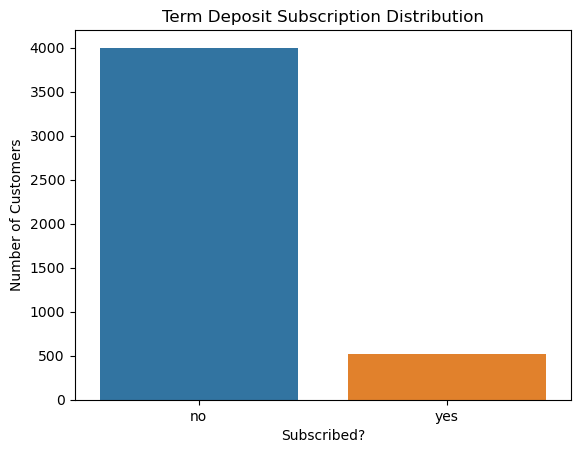

In [26]:
sns.countplot(data=df, x="y", hue="y", legend=False)
plt.title("Term Deposit Subscription Distribution")
plt.xlabel("Subscribed?")
plt.ylabel("Number of Customers")

In [27]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='object')

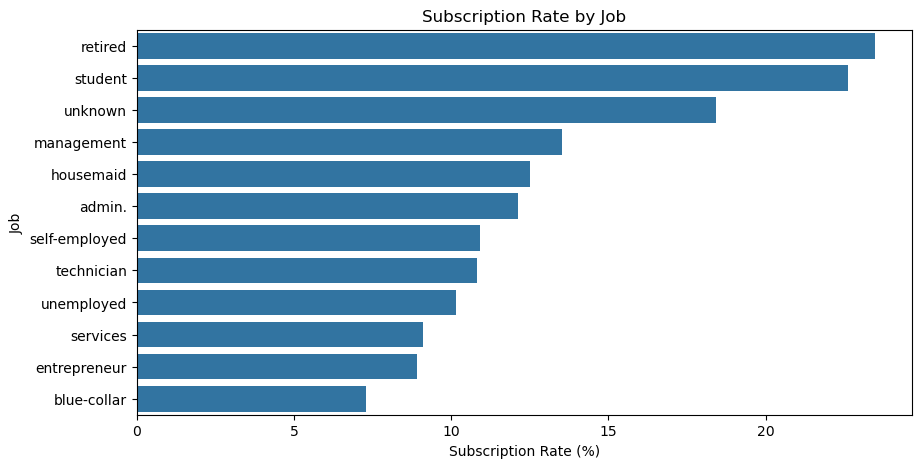

In [33]:
job_rate = (
    df.groupby('job',observed=True)['y']
        .apply(lambda s:s.eq('yes').mean()*100)
        .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=job_rate.values, y=job_rate.index)

plt.title("Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")
plt.show()

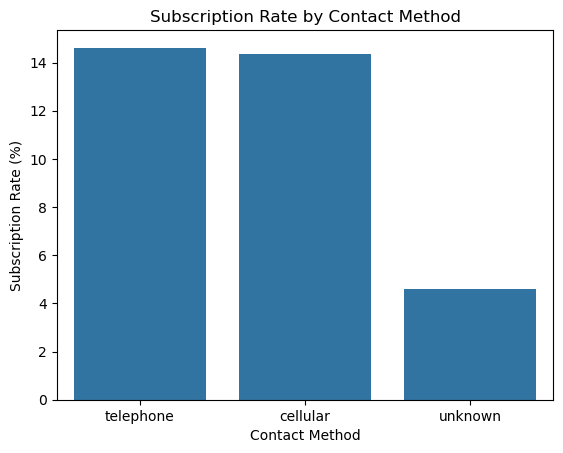

In [34]:
contact_rate = (
    df.groupby("contact", observed=True)["y"]
    .apply(lambda s: s.eq("yes").mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(x=contact_rate.index, y=contact_rate.values)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")
plt.show()

Text(0.5, 1.0, 'Age Distribution by Subscription Outcome')

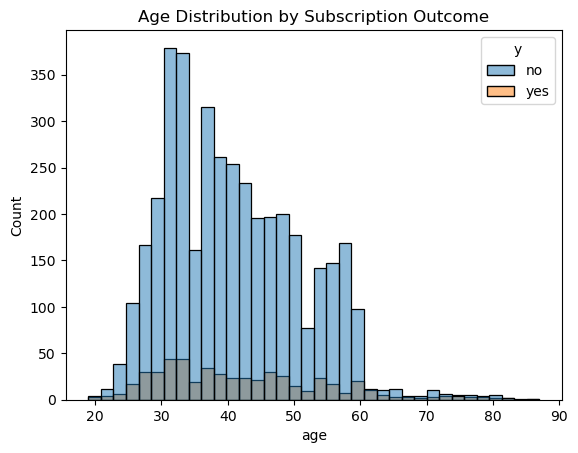

In [37]:
sns.histplot(data=df, x='age', hue='y')
plt.title("Age Distribution by Subscription Outcome")

Check Outliers

In [63]:
df.select_dtypes(include='number').columns

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')

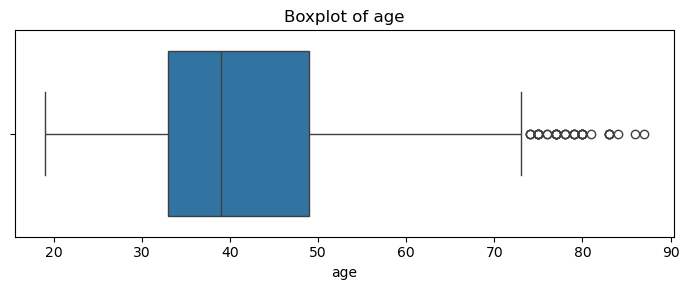

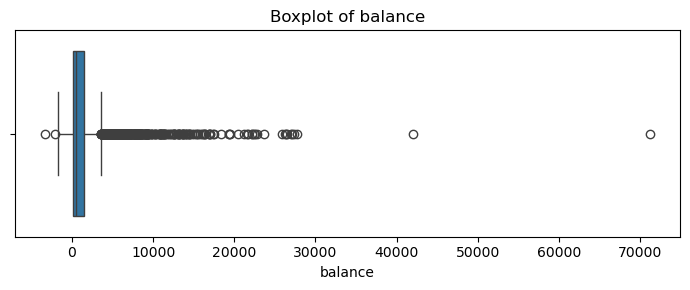

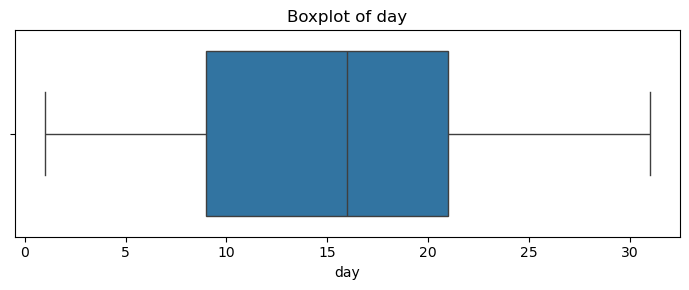

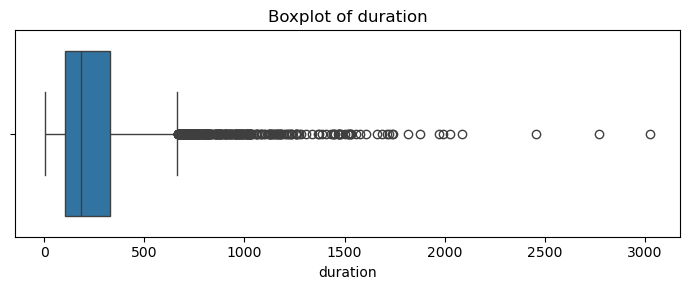

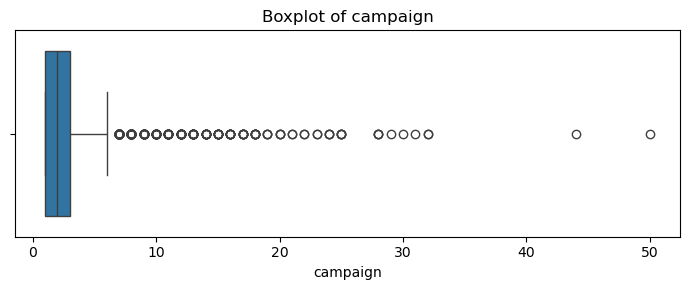

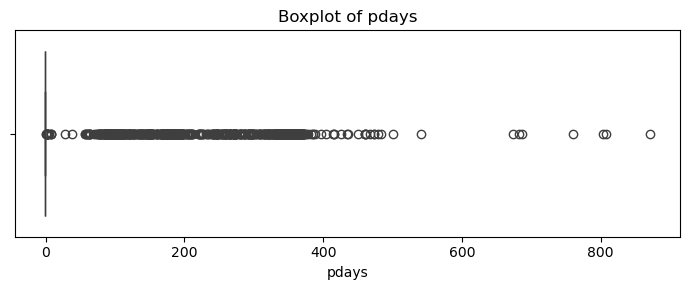

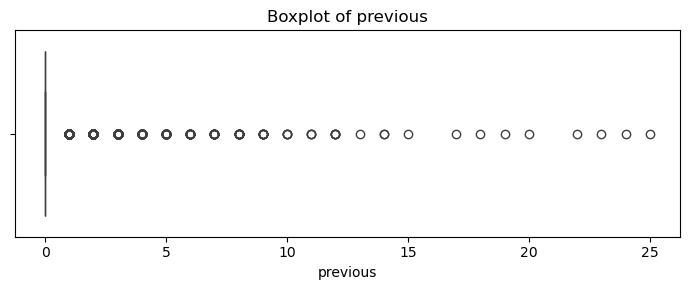

In [69]:
box_columns = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

for col in box_columns:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

## Data Cleaning

In [52]:
df.isnull().sum().sort_values(ascending=False).head(10)

age         0
day         0
poutcome    0
previous    0
pdays       0
campaign    0
duration    0
month       0
contact     0
job         0
dtype: int64

In [54]:
df.duplicated().sum()
#df = df.drop_duplicates().copy()

np.int64(0)

In [55]:
# Check unknown values in categorical columns
for col in df.select_dtypes(include="object").columns:
    print(col, (df[col] == "unknown").sum())

#To remove unknown
#for col in df.select_dtypes(include="object").columns:
#    df[col] = df[col].replace("unknown", "unknown")
#print("Actual null values:", df.isnull().sum().sum())

job 38
marital 0
education 187
default 0
housing 0
loan 0
contact 1324
month 0
poutcome 3705
y 0


## Feature engineering

We'll predict subscription before contacting the customer, so exclude duration to avoid using information only known after the call.

In [88]:
# Create a feature indicating whether the customer was previously contacted
df["previously_contacted"] = (df["pdays"] != -1).astype(int)

In [89]:
# removing 'duration' and 'pdays' columns now
df = df.drop(columns=['duration','pdays'])

In [90]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,previous,poutcome,y,previously_contacted
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,1,0,unknown,no,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,1,4,failure,no,1
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,1,1,failure,no,1
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,4,0,unknown,no,0
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,1,0,unknown,no,0


<Axes: >

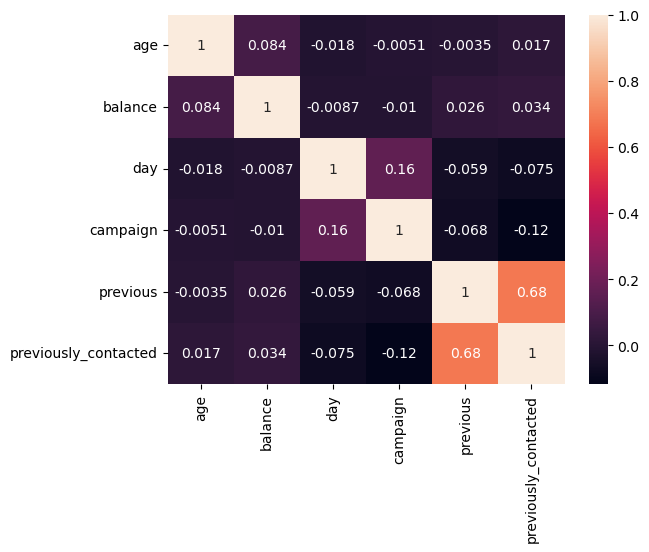

In [91]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## Data perprocessing

In [76]:
df_encode = pd.get_dummies(df,drop_first=True)

In [77]:
df_encode

,age,balance,day,campaign,previous,previously_contacted,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,y_yes
0,30,1787,19,1,0,0,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,33,4789,11,1,4,1,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
2,35,1350,16,1,1,1,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
3,30,1476,3,4,0,0,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,59,0,5,1,0,0,True,False,False,False,...,False,False,True,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,-333,30,5,0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4517,57,-3313,9,1,0,0,False,False,False,False,...,False,False,True,False,False,False,False,False,True,False
4518,57,295,19,11,0,0,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4519,28,1137,6,4,3,1,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False


In [83]:
df_encode = df_encode.astype(int)

In [84]:
df_encode

,age,balance,day,campaign,previous,previously_contacted,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,y_yes
0,30,1787,19,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,33,4789,11,1,4,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,35,1350,16,1,1,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,30,1476,3,4,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,59,0,5,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,-333,30,5,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4517,57,-3313,9,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4518,57,295,19,11,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4519,28,1137,6,4,3,1,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [92]:
from sklearn.preprocessing import StandardScaler
numerical_cols = ['age', 'balance', 'day']
scaler = StandardScaler()
df_encode[numerical_cols] = scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()

,age,balance,day,campaign,previous,previously_contacted,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,y_yes
0,-1.056270,0.121072,0.374052,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0
1,-0.772583,1.118644,-0.596026,1,4,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,-0.583458,-0.024144,0.010273,1,1,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,-1.056270,0.017726,-1.566105,4,0,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,1.686036,-0.472753,-1.323585,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0


Separating X and y 

In [94]:
X = df_encode.drop(['y_yes'], axis = 1)
y = df_encode['y_yes']

## Algorithm

In [103]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 8.1 MB/s eta 0:00:06
   -- ------------------------------------- 2.9/48.9 MB 8.8 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/48.9 MB 9.6 MB/s eta 0:00:05
   ----- ---------------------------------- 6.8/48.9 MB 9.2 MB/s eta 0:00:05
   ------- -------------------------------- 9.4/48.9 MB 9.9 MB/s eta 0:00:05
   --------- ------------------------------ 11.8/48.9 MB 10.1 MB/s eta 0:00:04
   ----------- ---------------------------- 13.6/48.9 MB 10.0 MB/s eta 0:00:04
   ------------ --------------------------- 15.7/48.9 MB 9.9 MB/s eta 0:00:04
   -------------- ------------------------- 17.3/48.9 MB 9.7 MB/s eta 0:00:04
   ---------------- ----------------------- 19.7/48.9 MB 9.8 MB/s eta 0:00:03
   ----------------- ---------------------- 22.0/48.9 MB 10.0 MB/s eta 0:00:03
   ------------------- -------------------- 24.4/48.9 MB 10.1 MB/s eta 0:0

In [104]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [105]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [106]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.fit_transform(X_test)

In [107]:
models = {
    'Logistic Regression' : LogisticRegression(),
    'KNN' : KNeighborsClassifier(),
    'Naive Bayes' : GaussianNB(),
    'Decision Tree' : DecisionTreeClassifier(),
    'SVM' : SVC(),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42,eval_metric='logloss')
}

In [108]:
result = []

In [109]:
for name,model in models.items():
    model.fit(x_train_scaled, y_train)
    y_pred = model.predict(x_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred) 
    result.append({
        'Model': name,
        'Accuracy': round(acc,4),
        'f1 score': round(f1,4)
    })

In [110]:
result

[{'Model': 'Logistic Regression', 'Accuracy': 0.8939, 'f1 score': 0.2258},
 {'Model': 'KNN', 'Accuracy': 0.8807, 'f1 score': 0.194},
 {'Model': 'Naive Bayes', 'Accuracy': 0.821, 'f1 score': 0.2957},
 {'Model': 'Decision Tree', 'Accuracy': 0.8265, 'f1 score': 0.2698},
 {'Model': 'SVM', 'Accuracy': 0.8928, 'f1 score': 0.1709},
 {'Model': 'Random Forest', 'Accuracy': 0.8972, 'f1 score': 0.2185},
 {'Model': 'XGBoost', 'Accuracy': 0.8796, 'f1 score': 0.2378}]

In [113]:
rf = models["Random Forest"]
y_pred = rf.predict(x_test_scaled)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.99      0.95       807
           1       0.62      0.13      0.22        98

    accuracy                           0.90       905
   macro avg       0.76      0.56      0.58       905
weighted avg       0.87      0.90      0.87       905



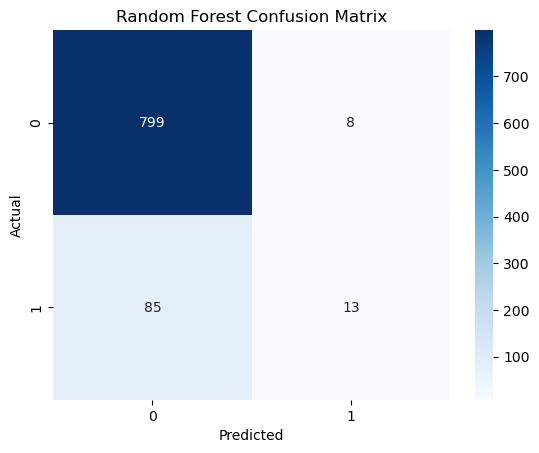

In [115]:
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

My Random Forest model has 90% accuracy, but it's missing most customers who actually subscribe. This is a useful finding for my project because it shows why accuracy alone can be misleading. <br>
`No: 807 customers` <br>
`Yes: 98 customers`

This is happening because my dataset is imbalanced: there are many more no outcomes than yes outcomes. Random Forest tends to favour the majority class when using its default classification threshold. <br>

There are ways we can make our dataset balanced: <br>
Method 1: `SMOTE` <br>
Creates synthetic yes examples based on existing minority-class examples. <br>
Good method to try <br>
It doesn't simply duplicate existing rows; it generates new synthetic samples.

Method 2: `Random oversampling` <br>
Randomly duplicates existing yes rows until the minority class reaches your chosen size. <br>
Easy to implement, but duplicated examples can increase overfitting.

Method 3: `Random undersampling` <br>
Reduces the number of no rows rather than increasing yes.

It can help balance the classes, but you may lose useful information.

In [116]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(x_train_scaled, y_train)

y_pred = rf_balanced.predict(x_test_scaled)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.99      0.95       807
           1       0.71      0.12      0.21        98

    accuracy                           0.90       905
   macro avg       0.80      0.56      0.58       905
weighted avg       0.88      0.90      0.87       905



It has improved a little bit but let's improve the threshold

In [118]:
y_prob = rf_balanced.predict_proba(x_test_scaled)[:, 1]

threshold = 0.25
y_pred_adjusted = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_pred_adjusted))

              precision    recall  f1-score   support

           0       0.92      0.94      0.93       807
           1       0.38      0.30      0.33        98

    accuracy                           0.87       905
   macro avg       0.65      0.62      0.63       905
weighted avg       0.86      0.87      0.86       905



In [123]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [132]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

# Balance training data only
ros = RandomOverSampler(random_state=42)

x_train_resampled, y_train_resampled = ros.fit_resample(X_train, y_train)

print("Before:", Counter(y_train))
print("After:", Counter(y_train_resampled))

Before: Counter({0: 3193, 1: 423})
After: Counter({0: 3193, 1: 3193})


In [133]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train_resampled)
x_test_scaled = scaler.transform(X_test)

In [134]:
models = {
    'Logistic Regression' : LogisticRegression(),
    'KNN' : KNeighborsClassifier(),
    'Naive Bayes' : GaussianNB(),
    'Decision Tree' : DecisionTreeClassifier(),
    'SVM' : SVC(),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42,eval_metric='logloss')
}

In [135]:
result = []

In [137]:
for name,model in models.items():
    model.fit(x_train_scaled, y_train_resampled)
    y_pred = model.predict(x_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred) 
    result.append({
        'Model': name,
        'Accuracy': round(acc,4),
        'f1 score': round(f1,4)
    })

In [138]:
result

[{'Model': 'Logistic Regression', 'Accuracy': 0.7039, 'f1 score': 0.2757},
 {'Model': 'KNN', 'Accuracy': 0.7072, 'f1 score': 0.2363},
 {'Model': 'Naive Bayes', 'Accuracy': 0.8088, 'f1 score': 0.2939},
 {'Model': 'Decision Tree', 'Accuracy': 0.8331, 'f1 score': 0.2844},
 {'Model': 'SVM', 'Accuracy': 0.7878, 'f1 score': 0.3379},
 {'Model': 'Random Forest', 'Accuracy': 0.8939, 'f1 score': 0.3143},
 {'Model': 'XGBoost', 'Accuracy': 0.8641, 'f1 score': 0.3422}]

Random Forest is giving the best accuracy of 89.3%

## Pickle and Joblib

In [139]:
import joblib
joblib.dump(models['Random Forest'], 'RF_model_bank_marketing.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(X.columns.tolist(), 'columns.pkl')

['columns.pkl']